# **BIGRAM CHARECTER LEVEL LANGUAGE MODEL**

# Approach 1: The Statistical Counting Approach (Frequency Lookup Table)

This first method we implemented is a classic **statistical count-based lookup table**. We explicitly counted every character transition in our dataset, smoothed the results, and turned them directly into a static probability matrix $P$.

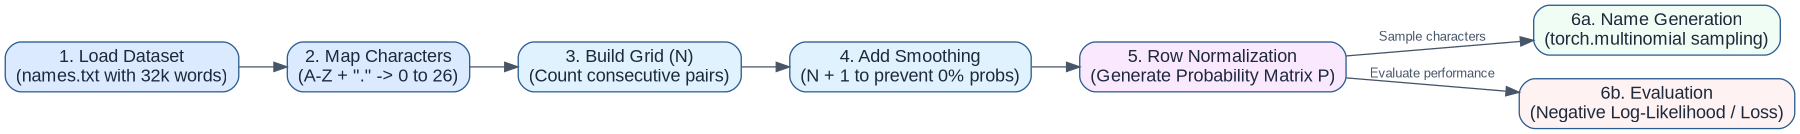

names.txt contains sample names, approx 32k words

In [7]:
words = open('../data/names.txt', 'r').read().splitlines()

In [8]:
words [ : 10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

Bigram model : Looks at two charecters only at a time

Bigrams

In [ ]:
b={}
for w in words:
  chs=["<s>"] + list(w) + ["<E>"]
  for ch1,ch2 in zip(chs,chs[1:]):
    bigram= (ch1,ch2)
    b[bigram]=b.get(bigram,0)+1


In [10]:
sorted(b.items(), key = lambda kv : -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<s>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<s>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<s>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<s>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<s>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<s>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<s>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<s>', 'l'), 1572),
 (('<s>', 'c'), 1542),
 (('<s>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [11]:
import torch

In [12]:
N = torch.zeros((27, 27), dtype=torch.int32)
N

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0],


In [13]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)} # STRING TO INTEGER MAPPING
stoi['.'] = 0


In [14]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1


In [15]:
N

tensor([[   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
         1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
          134,  535,  929],
        [6640,  556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568,
         2528, 1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,
          182, 2050,  435],
        [ 114,  321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,
          103,    0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,
            0,   83,    0],
        [  97,  815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,
          116,    0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,
            3,  104,    4],
        [ 516, 1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,
           60,   30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,
            0,  317,    1],
        [3983,  679,  121,  153,  384, 1271,   82,

In [16]:
itos = {i:s for s,i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

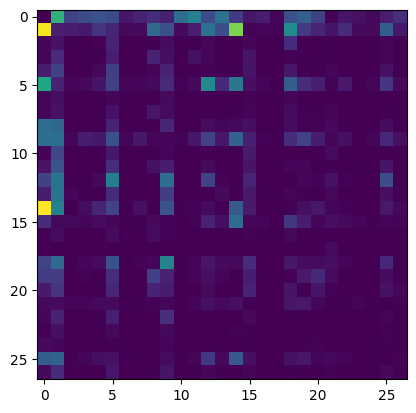

In [17]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

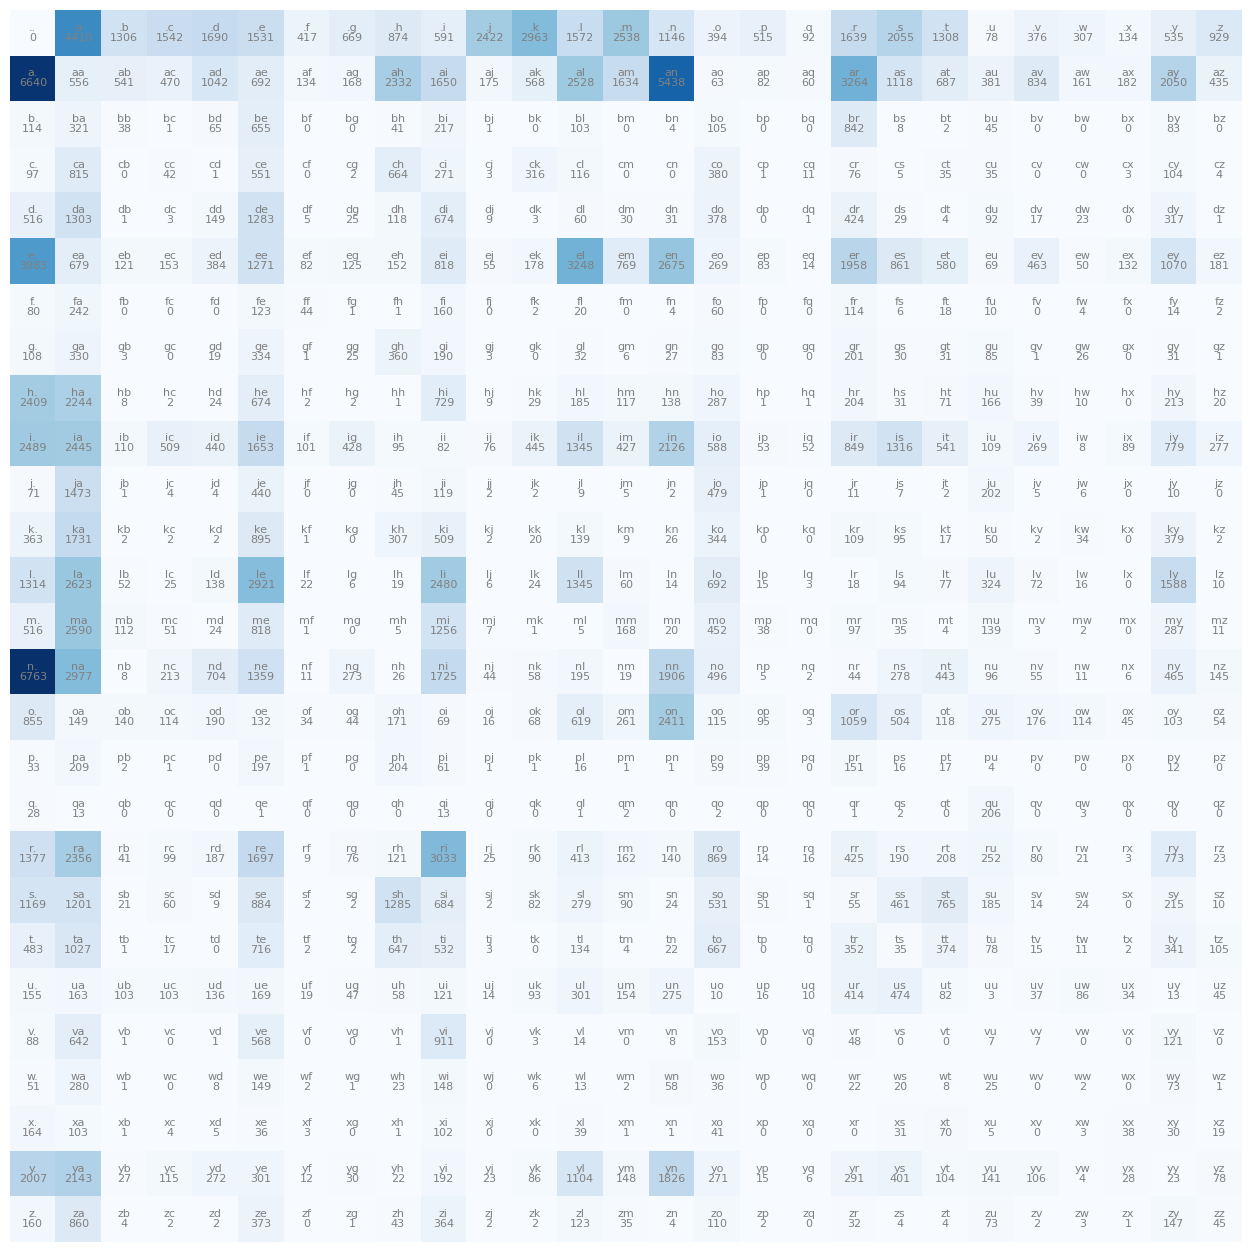

In [18]:
plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        ch1 = itos[i]
        ch2 = itos[j]
        plt.text(j, i, f'{ch1}{ch2}', ha="center", va="bottom", color='gray', fontsize=8)
        plt.text(j, i, f'{N[i, j].item()}', ha="center", va="top", color='gray', fontsize=8)
plt.axis('off');

In [19]:
p = N[0].float()
p = p/ p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [20]:
g = torch.Generator().manual_seed(2147483647)
# Sample a character index from the start distribution using the generator
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print(f"Sampled index: {ix}, which maps to character: '{itos[ix]}'" )

Sampled index: 3, which maps to character: 'c'


In [21]:
# Normalize the rows of N to create a probability matrix P
# Adding 1 for model smoothing (prevents 0 probability division and infinite loss later)
P = (N + 1).float() # 1 is added to N to smoothen out the probabilities because for zero probs, log will be infinity and it will disturb the entire workflow.
P /= P.sum(dim=1, keepdim=True)

g = torch.Generator().manual_seed(2147483647)
p=torch.rand(3, generator =g)
p= p/p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [22]:
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix = 0 # Start token '.'
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0: # End token '.' reached
            break
    print(''.join(out[:-1]))

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda


In [23]:
log_likelihood = 0.0
n = 0

for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1, ix2]
    logprob = torch.log(prob)
    log_likelihood += logprob
    n += 1

print(f'Log-Likelihood: {log_likelihood.item():.4f}')
nll = -log_likelihood
print(f'Negative Log-Likelihood (NLL): {nll.item():.4f}')
print(f'Average NLL (Loss): {nll.item()/n:.4f}')

Log-Likelihood: -559951.5625
Negative Log-Likelihood (NLL): 559951.5625
Average NLL (Loss): 2.4544


 Summary of What We Have Done So Far

1. **Loaded the Dataset**: We read a text file containing around 32,000 human names and looked at the first few examples (like *emma*, *olivia*, etc.).

2. **Understood Bigrams**: We decided to build a simple model that predicts the next character by only looking at the current character (pairs of characters are called "bigrams"). We also added starting and ending markers (`.`) to know where a name begins and ends.

3. **Mapped Characters to Numbers**: Because computers work with numbers rather than text, we created a dictionary mapping each of the 26 letters and our special `.` marker to numbers from 0 to 26.

4. **Counted Pairs (The Matrix)**: We went through all the names in our dataset, counted how often each character follows another, and stored these counts in a $27 \times 27$ grid (a 2D grid/matrix).

5. **Created a Probability Grid**: We converted those raw counts into percentages (probabilities). To make sure we never get a $0\%$ chance for combinations we didn't see in the dataset, we added a count of `1` to every pair as a safety cushion (smoothing).

6. **Generated New Names**: Using our probability grid, we sampled characters one by one to generate 10 brand-new, synthetic names.

7. **Measured Performance (Loss)**: We evaluated how well our grid represents the actual dataset. By checking how "surprised" our model is by the real names, we calculated an average performance score (Loss) of **2.4544**. A lower score means a better, more accurate model.

# Approach 2: The Neural Network Approach

Now, we will tackle the exact same bigram language modeling task using a simple single-layer neural network.

Instead of counting the occurrences of each bigram explicitly and storing them in a static matrix, we will feed our inputs into a linear layer, apply a softmax function to get our output probabilities, and optimize our weights using gradient descent by minimizing the Negative Log-Likelihood (NLL) loss.

In [24]:
# create a training set of bigrams
xs, ys = [],[]
for w in words :
  chs = ['.'] + list(w) + ['.']
  for ch1,ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

In [25]:
# Let's check how many bigram training examples we have
print(f"Total training examples: {len(xs)}")

# Let's inspect the first 5 input/target pairs
for i in range(5):
    print(f"Example {i+1}: char index input {xs[i].item()} ('{itos[xs[i].item()]}') -> target index {ys[i].item()} ('{itos[ys[i].item()]}')")

Total training examples: 228146
Example 1: char index input 0 ('.') -> target index 5 ('e')
Example 2: char index input 5 ('e') -> target index 13 ('m')
Example 3: char index input 13 ('m') -> target index 13 ('m')
Example 4: char index input 13 ('m') -> target index 1 ('a')
Example 5: char index input 1 ('a') -> target index 0 ('.')


In [26]:
import torch.nn.functional as F

# Convert the input character indices (xs) into 27-dimensional one-hot encoded float vectors
xenc = F.one_hot(xs, num_classes=27).float()

print(f"Shape of xs: {xs.shape}")
print(f"Shape of one-hot encoded xenc: {xenc.shape}")

Shape of xs: torch.Size([228146])
Shape of one-hot encoded xenc: torch.Size([228146, 27])


In [27]:
# Let's inspect the first input index and its corresponding one-hot encoded vector
print(f"First input index (character '{itos[xs[0].item()]}'): {xs[0].item()}")
print(f"One-hot encoded representation:\n{xenc[0]}")

First input index (character '.'): 0
One-hot encoded representation:
tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [31]:
# Initialize random weights generator
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g)

# Forward pass
logits = xenc @ W # log of counts ( log (w*x)) # here bias is put as 0
counts = logits.exp() # equivalent to the N matrix
probs = counts / counts.sum(1, keepdims=True) #softmax activation = e power z divided bu sum of e power z
probs

tensor([[0.0607, 0.0100, 0.0123,  ..., 0.0118, 0.1537, 0.1459],
        [0.0290, 0.0796, 0.0248,  ..., 0.0118, 0.0022, 0.0472],
        [0.0312, 0.0737, 0.0484,  ..., 0.1204, 0.0469, 0.0126],
        ...,
        [0.0301, 0.0080, 0.0090,  ..., 0.0125, 0.0531, 0.0111],
        [0.0634, 0.0270, 0.0101,  ..., 0.0833, 0.0175, 0.0517],
        [0.0308, 0.0113, 0.0178,  ..., 0.0190, 0.0116, 0.0562]])

In [33]:
# Let's check the sum of the first row (the first training example)
print("Sum of the first row:", probs[0].sum().item())

# Let's check the sum of each row across the first dimension (should be 1.0 for all 228,146 rows)
row_sums = probs.sum(dim=1)
print("Shape of row sums:", row_sums.shape)
print("First 5 row sums:", row_sums[:5])

Sum of the first row: 1.0000001192092896
Shape of row sums: torch.Size([228146])
First 5 row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [35]:
# Let's look at the actual probabilities assigned for '.emma.'
target_word = '.emma.'

print(f"Probabilities for each character transition in '{target_word}':\n")
for i in range(len(target_word) - 1):
    ch_in = target_word[i]
    ch_out = target_word[i+1]

    # Get indices
    ix_in = stoi[ch_in]
    ix_out = stoi[ch_out]

    # The network's assigned probability for transitioning from ch_in to ch_out
    # We can fetch this directly from our probs tensor for the corresponding training examples
    # (The first 5 training examples in our dataset happen to correspond to 'emma')
    prob_val = probs[i, ix_out].item()

    print(f"Transition: '{ch_in}' -> '{ch_out}'")
    print(f"  Index: {ix_in} -> {ix_out}")
    print(f"  Assigned Probability: {prob_val:.4f} ({prob_val * 100:.2f}%)\n")

Probabilities for each character transition in '.emma.':

Transition: '.' -> 'e'
  Index: 0 -> 5
  Assigned Probability: 0.0123 (1.23%)

Transition: 'e' -> 'm'
  Index: 5 -> 13
  Assigned Probability: 0.0181 (1.81%)

Transition: 'm' -> 'm'
  Index: 13 -> 13
  Assigned Probability: 0.0267 (2.67%)

Transition: 'm' -> 'a'
  Index: 13 -> 1
  Assigned Probability: 0.0737 (7.37%)

Transition: 'a' -> '.'
  Index: 1 -> 0
  Assigned Probability: 0.0150 (1.50%)



In [37]:
# We have our targets (ys) and our predicted probabilities (probs)
# Let's extract the probability assigned to the correct next character for each training example

# We index probs using the row index (0 to 228145) and the correct column index given by ys
assigned_probs = probs[torch.arange(len(ys)), ys]

# Calculate negative log-likelihood for each example
log_likelihoods = torch.log(assigned_probs)
loss = -log_likelihoods.mean()

print(f"Average Negative Log-Likelihood (Loss): {loss.item():.4f}")

Average Negative Log-Likelihood (Loss): 3.7590


### Defining the Loss Function

In our neural network, we want to maximize the probability that the model assigns to the correct next character ($y$). This is equivalent to minimizing the **Negative Log-Likelihood (NLL)** loss.

Mathematically, for a single training example $(x, y)$, where our model outputs a probability distribution $P$, the loss is:

$$\text{Loss} = -\log(P[y])$$

For a full batch of size $M$, we take the average loss:

$$\text{Average Loss} = -\frac{1}{M} \sum_{i=1}^{M} \log(P^{(i)}[y^{(i)}])$$

We can calculate this manually using our computed `probs`, or directly from our `logits` using PyTorch's highly optimized, numerically stable `F.cross_entropy` function.

In [38]:
# Method 1: Manual Negative Log-Likelihood (from scratch)
manual_loss = -probs[torch.arange(len(ys)), ys].log().mean()
print(f"Method 1 (Manual NLL Loss): {manual_loss.item():.4f}")

# Method 2: PyTorch's Built-in Cross Entropy (using logits directly)
# This is mathematically identical, but avoids underflow/overflow issues with exp()
built_in_loss = F.cross_entropy(logits, ys)
print(f"Method 2 (F.cross_entropy Loss): {built_in_loss.item():.4f}")

Method 1 (Manual NLL Loss): 3.7590
Method 2 (F.cross_entropy Loss): 3.7590


### Backward Pass and Weight Update

Now we will perform a full step of training:
1. **Forward Pass:** Compute logits, probabilities, and the average loss.
2. **Backward Pass:** Calculate the gradients for our weights $W$ using backpropagation.
3. **Update:** Update our weights using gradient descent: $W = W - \eta \cdot \nabla_W \text{Loss}$ where $\eta$ is our learning rate.

In [39]:
# 1. Initialize weights with gradient tracking enabled
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

# 2. Forward pass
logits = xenc @ W
loss = F.cross_entropy(logits, ys)
print(f"Loss before backward pass: {loss.item():.4f}")

# 3. Backward pass
# Reset gradients if there are any, then backward
if W.grad is not None:
    W.grad.zero_()
loss.backward()

# 4. Weight update (gradient descent)
learning_rate = 50.0
with torch.no_grad():
    W.data -= learning_rate * W.grad

# 5. Forward pass again with the updated weights to verify the loss went down!
with torch.no_grad():
    new_logits = xenc @ W
    new_loss = F.cross_entropy(new_logits, ys)
    print(f"Loss after 1 update step:  {new_loss.item():.4f}")

Loss before backward pass: 3.7590
Loss after 1 update step:  3.3711


### Training Loop: Running Gradient Descent Iteratively

Now we will wrap our training steps into a simple loop to iteratively optimize the parameters $W$.

In [42]:
# 1. Re-initialize weights with gradient tracking enabled
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

# Hyperparameters
epochs = 1000
learning_rate = 50.0

# Optimization loop
for k in range(epochs):
    # Forward pass
    logits = xenc @ W
    loss = F.cross_entropy(logits, ys)

    # Backward pass
    W.grad = None  # More efficient way in PyTorch to zero out gradients
    loss.backward()

    # Weight update
    W.data -= learning_rate * W.grad

    # Print progress
    if (k + 1) % 10 == 0 or k == 0:
        print(f"Iteration {k+1:3d} / {epochs} | Loss: {loss.item():.4f}")

Iteration   1 / 1000 | Loss: 3.7590
Iteration  10 / 1000 | Loss: 2.7115
Iteration  20 / 1000 | Loss: 2.5794
Iteration  30 / 1000 | Loss: 2.5332
Iteration  40 / 1000 | Loss: 2.5103
Iteration  50 / 1000 | Loss: 2.4971
Iteration  60 / 1000 | Loss: 2.4887
Iteration  70 / 1000 | Loss: 2.4829
Iteration  80 / 1000 | Loss: 2.4787
Iteration  90 / 1000 | Loss: 2.4754
Iteration 100 / 1000 | Loss: 2.4729
Iteration 110 / 1000 | Loss: 2.4708
Iteration 120 / 1000 | Loss: 2.4692
Iteration 130 / 1000 | Loss: 2.4678
Iteration 140 / 1000 | Loss: 2.4667
Iteration 150 / 1000 | Loss: 2.4657
Iteration 160 / 1000 | Loss: 2.4648
Iteration 170 / 1000 | Loss: 2.4641
Iteration 180 / 1000 | Loss: 2.4635
Iteration 190 / 1000 | Loss: 2.4629
Iteration 200 / 1000 | Loss: 2.4624
Iteration 210 / 1000 | Loss: 2.4619
Iteration 220 / 1000 | Loss: 2.4615
Iteration 230 / 1000 | Loss: 2.4612
Iteration 240 / 1000 | Loss: 2.4608
Iteration 250 / 1000 | Loss: 2.4605
Iteration 260 / 1000 | Loss: 2.4602
Iteration 270 / 1000 | Loss:

### Sampling names from the trained Neural Network

In [48]:
g = torch.Generator().manual_seed(2147483647)

for i in range(30):
    out = []
    ix = 0 # start token '.'
    while True:
        # 1. One-hot encode the current character index
        xenc_sample = F.one_hot(torch.tensor([ix]), num_classes=27).float()

        # 2. Compute logits and transition probabilities using the trained weights W
        logits = xenc_sample @ W
        counts = logits.exp()
        p = counts / counts.sum(dim=1, keepdim=True)

        # 3. Sample the next character using our probability distribution
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])

        # 4. Stop if we sampled the end token '.'
        if ix == 0:
            break

    print(''.join(out[:-1]))

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda
ka
emimmsade
enkaviyny
fobspihinivenvorhlasu
dsor
br
jol
pen
aisan
ja
feniee
zem
deru
firit
gaikajahahbevare
kiysthelenaririenah
keen
x
al
kal


### Comparing Learned Weights $W$ with Original Frequencies $N$
We can visualize the exponentiated weights $e^W$ and compare them directly with the smoothed frequency matrix $N+1$.

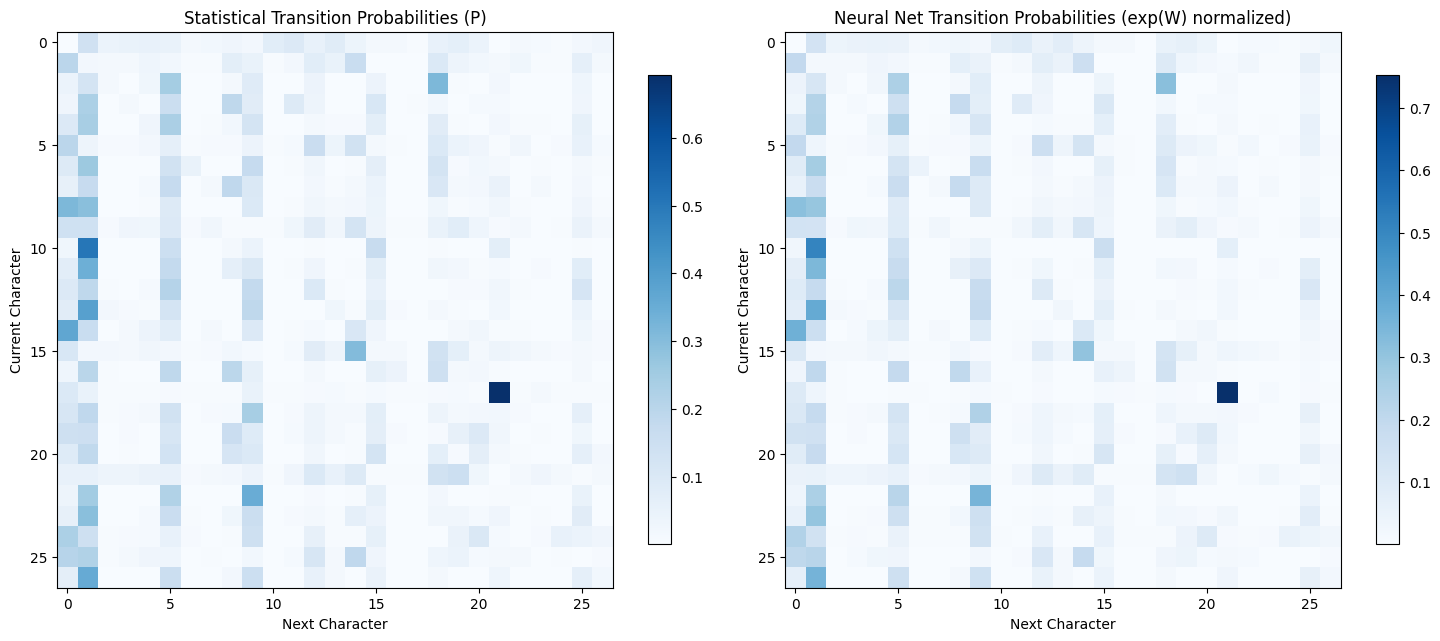

Correlation between Statistical and Neural probabilities: 0.999273


In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Exponentiate W to put it in the same scale as counts
exp_W = torch.exp(W).detach().cpu().numpy()
smoothed_N = (N + 1).float().cpu().numpy()

# Normalize both to represent transition probabilities for a direct comparison
P_neural = exp_W / exp_W.sum(axis=1, keepdims=True)
P_statistical = smoothed_N / smoothed_N.sum(axis=1, keepdims=True)

# Plot the two probability distributions side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

im1 = axes[0].imshow(P_statistical, cmap='Blues')
axes[0].set_title('Statistical Transition Probabilities (P)')
axes[0].set_xlabel('Next Character')
axes[0].set_ylabel('Current Character')
fig.colorbar(im1, ax=axes[0], shrink=0.7)

im2 = axes[1].imshow(P_neural, cmap='Blues')
axes[1].set_title('Neural Net Transition Probabilities (exp(W) normalized)')
axes[1].set_xlabel('Next Character')
axes[1].set_ylabel('Current Character')
fig.colorbar(im2, ax=axes[1], shrink=0.7)

plt.tight_layout()
plt.show()

# Let's calculate the correlation coefficient between the two matrices
correlation = np.corrcoef(P_statistical.flatten(), P_neural.flatten())[0, 1]
print(f"Correlation between Statistical and Neural probabilities: {correlation:.6f}")